<a href="https://colab.research.google.com/github/ShubhGuPTA-cmd/ML-experiments/blob/main/exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

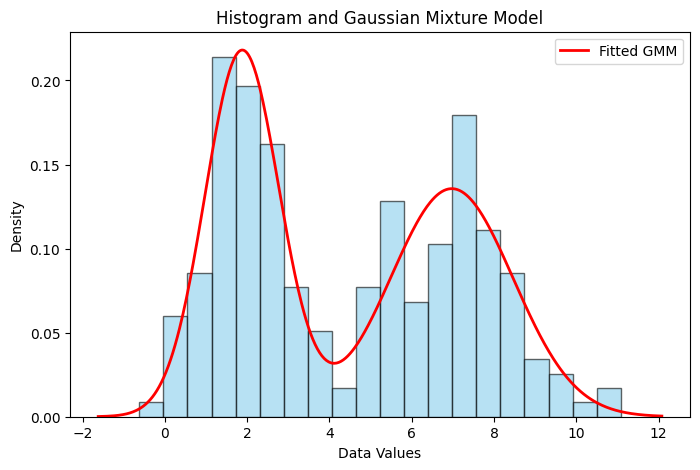

Estimated means: [1.8796237  6.97444511]
Estimated variances: [0.81478987 2.22686777]
Component weights: [0.49258644 0.50741356]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Generate 100 data points from each Gaussian distribution
np.random.seed(42)

data1 = np.random.normal(loc=2, scale=1, size=100)
data2 = np.random.normal(loc=7, scale=1.5, size=100)

# Combine both distributions
X = np.concatenate([data1, data2]).reshape(-1, 1)

# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(X, bins=20, density=True, alpha=0.6,
         color='skyblue', edgecolor='black')

# Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(X)

# Plot fitted Gaussian mixture density
x_axis = np.linspace(X.min() - 1, X.max() + 1, 500).reshape(-1, 1)
log_prob = gmm.score_samples(x_axis)
density = np.exp(log_prob)

plt.plot(x_axis, density, color='red', linewidth=2,
         label='Fitted GMM')

plt.title("Histogram and Gaussian Mixture Model")
plt.xlabel("Data Values")
plt.ylabel("Density")
plt.legend()
plt.show()

print("Estimated means:", gmm.means_.flatten())
print("Estimated variances:", gmm.covariances_.flatten())
print("Component weights:", gmm.weights_)

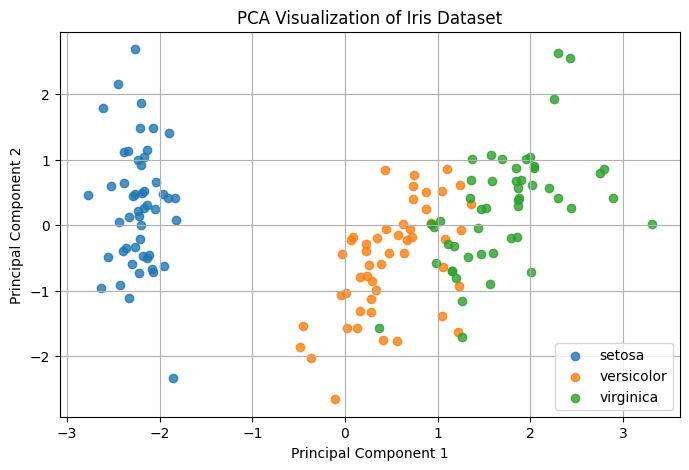

Original dimensions: (150, 4)
Reduced dimensions: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total variance retained: 95.81 %


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce 4 dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualize the reduced data
plt.figure(figsize=(8, 5))

for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

print("Original dimensions:", X.shape)
print("Reduced dimensions:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

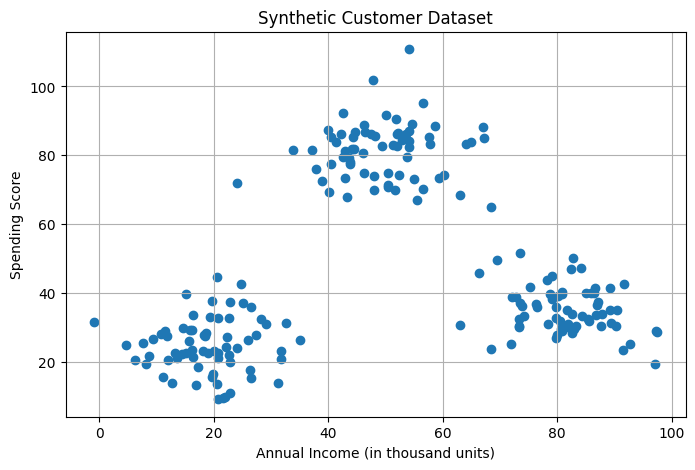

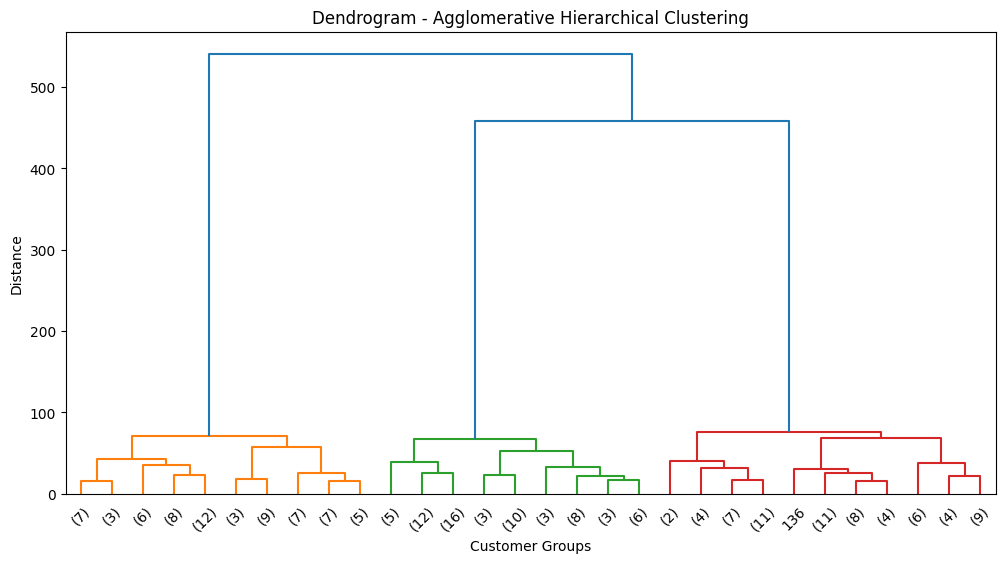

Number of customers: 200
Number of clusters: 3
First 10 cluster labels: [1 1 1 2 3 1 3 3 3 3]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Generate synthetic customer data
# Features: Annual Income and Spending Score
X_customers, _ = make_blobs(
    n_samples=200,
    centers=[[20, 25], [50, 80], [80, 35]],
    cluster_std=8,
    random_state=42
)

# Display customer data
plt.figure(figsize=(8, 5))
plt.scatter(X_customers[:, 0], X_customers[:, 1])
plt.xlabel("Annual Income (in thousand units)")
plt.ylabel("Spending Score")
plt.title("Synthetic Customer Dataset")
plt.grid(True)
plt.show()

# Perform hierarchical clustering
Z = linkage(X_customers, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Customer Groups")
plt.ylabel("Distance")
plt.show()

# Obtain 3 clusters from the hierarchy
labels_hc = fcluster(Z, t=3, criterion='maxclust')

print("Number of customers:", len(X_customers))
print("Number of clusters:", len(np.unique(labels_hc)))
print("First 10 cluster labels:", labels_hc[:10])

Final Centroids:
[[49.57382419 81.17860907]
 [19.01786556 24.68400235]
 [81.58339943 35.06383354]]

Number of iterations: 3
Inertia: 23219.63


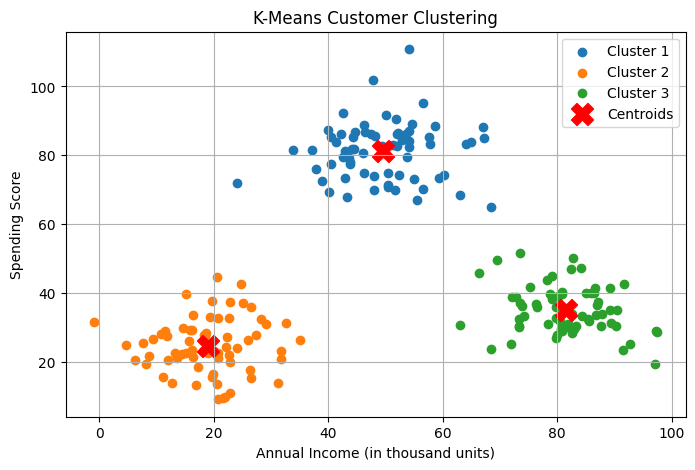

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Use the same dataset generated in Part (c)
X = X_customers

# Apply K-means
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=1,
    max_iter=100,
    tol=1e-4,
    random_state=42
)

kmeans.fit(X)

# Display final cluster centers
print("Final Centroids:")
print(kmeans.cluster_centers_)

print("\nNumber of iterations:", kmeans.n_iter_)
print("Inertia:", round(kmeans.inertia_, 2))

# Plot clusters and centroids
plt.figure(figsize=(8, 5))

for cluster in range(3):
    plt.scatter(
        X[kmeans.labels_ == cluster, 0],
        X[kmeans.labels_ == cluster, 1],
        label=f"Cluster {cluster + 1}"
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

plt.xlabel("Annual Income (in thousand units)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Clustering")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Initialize centroids using the same K-means++ strategy
initial_model = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=1,
    max_iter=1,
    random_state=42
)

initial_model.fit(X)

centroids = initial_model.cluster_centers_.copy()
records = []

for iteration in range(1, 101):

    # Assign each point to the nearest centroid
    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    # Calculate updated centroids
    new_centroids = centroids.copy()

    for cluster in range(3):
        points = X[labels == cluster]

        if len(points) > 0:
            new_centroids[cluster] = points.mean(axis=0)

    # Save iteration and centroid coordinates
    row = {"Iteration": iteration}

    for cluster in range(3):
        row[f"C{cluster+1}_Income"] = round(
            new_centroids[cluster, 0], 3
        )
        row[f"C{cluster+1}_Spending"] = round(
            new_centroids[cluster, 1], 3
        )

    records.append(row)

    # Stop when the centroids have converged
    if np.allclose(centroids, new_centroids, atol=1e-4):
        centroids = new_centroids
        break

    centroids = new_centroids

# Create the iteration table
centroid_table = pd.DataFrame(records)

print(centroid_table.to_string(index=False))

 Iteration  C1_Income  C1_Spending  C2_Income  C2_Spending  C3_Income  C3_Spending
         1     49.574       81.179     19.018       24.684     81.583       35.064
         2     49.574       81.179     19.018       24.684     81.583       35.064
